In [1]:
!git clone https://github.com/scheck-k/ste-gan.git
%cd ste-gan

Cloning into 'ste-gan'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 51 (delta 3), reused 51 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (51/51), 56.87 KiB | 2.11 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/kaggle/working/ste-gan


In [2]:
!pip install torch torchvision torchaudio
!pip install numpy librosa tqdm tensorboard pyyaml soundfile

# **Load And Unzip Data**

In [3]:
!wget -O clean_trainset_28spk_wav.zip \
"https://datashare.ed.ac.uk/bitstream/handle/10283/2791/clean_trainset_28spk_wav.zip?sequence=2&isAllowed=y"

--2026-02-26 10:02:15--  https://datashare.ed.ac.uk/bitstream/handle/10283/2791/clean_trainset_28spk_wav.zip?sequence=2&isAllowed=y
Resolving datashare.ed.ac.uk (datashare.ed.ac.uk)... 129.215.67.172
Connecting to datashare.ed.ac.uk (datashare.ed.ac.uk)|129.215.67.172|:443... connected.
HTTP request sent, awaiting response... 200 200
Length: 2486057279 (2.3G) [application/zip]
Saving to: ‘clean_trainset_28spk_wav.zip’

clean_trainset_28sp 100%[===================>]   2.31G  11.2MB/s    in 3m 22s  

2026-02-26 10:05:38 (11.7 MB/s) - ‘clean_trainset_28spk_wav.zip’ saved [2486057279/2486057279]



In [4]:
!unzip clean_trainset_28spk_wav.zip -d clean_data

Archive:  clean_trainset_28spk_wav.zip
   creating: clean_data/clean_trainset_28spk_wav/
  inflating: clean_data/clean_trainset_28spk_wav/p226_001.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_002.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_003.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_004.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_005.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_006.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_007.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_008.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_009.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_010.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_011.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_012.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_013.wav  
  inflating: clean_data/clean_trainset_28spk_wav/p226_014.wav  
  inflating: cl

In [5]:
!wget -O noisy_trainset_28spk_wav.zip \
"https://datashare.ed.ac.uk/bitstream/handle/10283/2791/noisy_trainset_28spk_wav.zip?sequence=6&isAllowed=y"

--2026-02-26 10:08:29--  https://datashare.ed.ac.uk/bitstream/handle/10283/2791/noisy_trainset_28spk_wav.zip?sequence=6&isAllowed=y
Resolving datashare.ed.ac.uk (datashare.ed.ac.uk)... 129.215.67.172
Connecting to datashare.ed.ac.uk (datashare.ed.ac.uk)|129.215.67.172|:443... connected.
HTTP request sent, awaiting response... 200 200
Length: 2830205201 (2.6G) [application/zip]
Saving to: ‘noisy_trainset_28spk_wav.zip’

noisy_trainset_28sp 100%[===================>]   2.64G  21.8MB/s    in 2m 11s  

2026-02-26 10:10:41 (20.7 MB/s) - ‘noisy_trainset_28spk_wav.zip’ saved [2830205201/2830205201]



In [6]:
!unzip noisy_trainset_28spk_wav.zip -d noisy_data

Archive:  noisy_trainset_28spk_wav.zip
   creating: noisy_data/noisy_trainset_28spk_wav/
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_001.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_002.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_003.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_004.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_005.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_006.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_007.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_008.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_009.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_010.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_011.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_012.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_013.wav  
  inflating: noisy_data/noisy_trainset_28spk_wav/p226_014.wav  
  inflating: no

In [7]:
import os

print("Working dir:", os.getcwd())
print("Folders:", os.listdir("/kaggle/working"))

Working dir: /kaggle/working/ste-gan
Folders: ['.virtual_documents', 'ste-gan']


In [8]:
import os

print(os.listdir("/kaggle/working"))

['.virtual_documents', 'ste-gan']


In [9]:
print(os.listdir("/kaggle/input"))

['datasets']


In [10]:
import os

clean_files = sorted(os.listdir("/kaggle/working/ste-gan/clean_data"))
noisy_files = sorted(os.listdir("/kaggle/working/ste-gan/noisy_data"))

print("Clean count:", len(clean_files))
print("Noisy count:", len(noisy_files))

print("First clean file:", clean_files[0])
print("First noisy file:", noisy_files[0])

Clean count: 1
Noisy count: 1
First clean file: clean_trainset_28spk_wav
First noisy file: noisy_trainset_28spk_wav


In [11]:
print(os.listdir("/kaggle/working/ste-gan/clean_data/clean_trainset_28spk_wav")[:5])

['p231_158.wav', 'p287_013.wav', 'p279_042.wav', 'p259_047.wav', 'p236_035.wav']


In [12]:
import os

clean_root = "/kaggle/working/ste-gan/clean_data/clean_trainset_28spk_wav"
noisy_root = "/kaggle/working/ste-gan/noisy_data/noisy_trainset_28spk_wav"

clean_files = sorted(os.listdir(clean_root))
noisy_files = sorted(os.listdir(noisy_root))

print("Number of clean files:", len(clean_files))
print("Number of noisy files:", len(noisy_files))

print("First clean file:", clean_files[0])
print("First noisy file:", noisy_files[0])

Number of clean files: 11572
Number of noisy files: 11572
First clean file: p226_001.wav
First noisy file: p226_001.wav


In [13]:
import torch
import torchaudio
import os

clean_root = "/kaggle/working/ste-gan/clean_data/clean_trainset_28spk_wav"
noisy_root = "/kaggle/working/ste-gan/noisy_data/noisy_trainset_28spk_wav"

files = sorted(os.listdir(clean_root))

clean_path = os.path.join(clean_root, files[0])
noisy_path = os.path.join(noisy_root, files[0])

clean, sr1 = torchaudio.load(clean_path)
noisy, sr2 = torchaudio.load(noisy_path)

print("Sample rate clean:", sr1)
print("Sample rate noisy:", sr2)

print("Clean shape before mono:", clean.shape)
print("Noisy shape before mono:", noisy.shape)

# تبدیل به mono
clean = clean.mean(dim=0, keepdim=True)
noisy = noisy.mean(dim=0, keepdim=True)

print("Clean shape after mono:", clean.shape)
print("Noisy shape after mono:", noisy.shape)

Sample rate clean: 48000
Sample rate noisy: 48000
Clean shape before mono: torch.Size([1, 109440])
Noisy shape before mono: torch.Size([1, 109440])
Clean shape after mono: torch.Size([1, 109440])
Noisy shape after mono: torch.Size([1, 109440])


In [14]:
import torchaudio
import torch

resampler = torchaudio.transforms.Resample(orig_freq=48000, new_freq=16000)

clean_resampled = resampler(clean)
noisy_resampled = resampler(noisy)

print("New shape clean:", clean_resampled.shape)
print("New shape noisy:", noisy_resampled.shape)

New shape clean: torch.Size([1, 36480])
New shape noisy: torch.Size([1, 36480])


In [15]:
import os
import torch
import torchaudio
from torch.utils.data import Dataset

class CustomSpeechDataset(Dataset):
    def __init__(self, clean_root, noisy_root, segment_length=16384):
        self.clean_root = clean_root
        self.noisy_root = noisy_root
        self.segment_length = segment_length
        
        self.files = sorted(os.listdir(clean_root))
        
        self.resampler = torchaudio.transforms.Resample(
            orig_freq=48000,
            new_freq=16000
        )

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        filename = self.files[idx]

        clean_path = os.path.join(self.clean_root, filename)
        noisy_path = os.path.join(self.noisy_root, filename)

        clean, _ = torchaudio.load(clean_path)
        noisy, _ = torchaudio.load(noisy_path)

        # enforce mono
        clean = clean.mean(dim=0, keepdim=True)
        noisy = noisy.mean(dim=0, keepdim=True)

        # resample to 16k
        clean = self.resampler(clean)
        noisy = self.resampler(noisy)

        # align length
        min_len = min(clean.shape[-1], noisy.shape[-1])
        clean = clean[:, :min_len]
        noisy = noisy[:, :min_len]

        # random crop for GAN stability
        if min_len > self.segment_length:
            start = torch.randint(0, min_len - self.segment_length, (1,))
            clean = clean[:, start:start+self.segment_length]
            noisy = noisy[:, start:start+self.segment_length]

        return noisy, clean

In [16]:
clean_root = "/kaggle/working/ste-gan/clean_data/clean_trainset_28spk_wav"
noisy_root = "/kaggle/working/ste-gan/noisy_data/noisy_trainset_28spk_wav"

dataset = CustomSpeechDataset(clean_root, noisy_root)

print("Total samples:", len(dataset))

x, y = dataset[0]

print("Noisy shape:", x.shape)
print("Clean shape:", y.shape)

Total samples: 11572
Noisy shape: torch.Size([1, 16384])
Clean shape: torch.Size([1, 16384])


In [17]:
from torch.utils.data import random_split, DataLoader

total_size = len(dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size]
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

Train: 9257
Validation: 1157
Test: 1158


In [18]:
file_path = "/kaggle/working/ste-gan/ste_gan/models/generator.py"

new_code = """

class WaveformGenerator(nn.Module):
    '''
    Modified STE-GAN Generator
    Noisy waveform -> Clean waveform
    '''

    def __init__(self, channels=64):
        super().__init__()

        self.encoder = nn.Sequential(
            WNConv1d(1, channels, kernel_size=15, stride=1, padding=7),
            nn.LeakyReLU(0.2),

            WNConv1d(channels, channels*2, kernel_size=15, stride=2, padding=7),
            nn.LeakyReLU(0.2),

            WNConv1d(channels*2, channels*4, kernel_size=15, stride=2, padding=7),
            nn.LeakyReLU(0.2),
        )

        self.resblocks = nn.Sequential(
            GBlock(channels*4, channels*4),
            GBlock(channels*4, channels*4),
            GBlock(channels*4, channels*4),
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose1d(channels*4, channels*2, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.ConvTranspose1d(channels*2, channels, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            WNConv1d(channels, 1, kernel_size=15, stride=1, padding=7),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.resblocks(x)
        x = self.decoder(x)
        return x
"""

with open(file_path, "a") as f:
    f.write(new_code)

print("WaveformGenerator added successfully!")

WaveformGenerator added successfully!


In [21]:
import sys
sys.path.append("/kaggle/working/ste-gan")

from ste_gan.models.generator import WaveformGenerator
import torch

G = WaveformGenerator()
x = torch.randn(4,1,16384)
y = G(x)

print("Output shape:", y.shape)

Output shape: torch.Size([4, 1, 16384])


In [20]:
import ste_gan.models.discriminator as disc
print([n for n in dir(disc) if not n.startswith("_")])

['Discriminator', 'DiscriminatorP', 'DiscriminatorS', 'DiscriminatorSmall', 'DiscriminatorSmallerP', 'DiscriminatorSmallerS', 'F', 'NormedConv1d', 'NormedConv2d', 'init_emg_discriminators', 'logging', 'nn', 'omegaconf', 'rearrange', 'repeat', 'spectral_norm', 'ste_gan', 'torch', 'weight_norm']


In [22]:
file_path = "/kaggle/working/ste-gan/ste_gan/models/discriminator.py"

new_code = """

class WaveformDiscriminator(nn.Module):
    '''
    Multi-Scale Waveform Discriminator
    for Speech Enhancement
    '''

    def __init__(self):
        super().__init__()

        def disc_block(in_ch, out_ch, stride):
            return nn.Sequential(
                spectral_norm(nn.Conv1d(in_ch, out_ch, 15, stride=stride, padding=7)),
                nn.LeakyReLU(0.2)
            )

        self.scale1 = nn.Sequential(
            disc_block(1, 16, 1),
            disc_block(16, 64, 2),
            disc_block(64, 256, 2),
            spectral_norm(nn.Conv1d(256, 1, 3, padding=1))
        )

        self.scale2 = nn.Sequential(
            disc_block(1, 16, 1),
            disc_block(16, 64, 2),
            disc_block(64, 256, 2),
            spectral_norm(nn.Conv1d(256, 1, 3, padding=1))
        )

        self.scale3 = nn.Sequential(
            disc_block(1, 16, 1),
            disc_block(16, 64, 2),
            disc_block(64, 256, 2),
            spectral_norm(nn.Conv1d(256, 1, 3, padding=1))
        )

        self.avgpool = nn.AvgPool1d(4, stride=2, padding=1)

    def forward(self, x):
        outputs = []

        out1 = self.scale1(x)
        outputs.append(out1)

        x2 = self.avgpool(x)
        out2 = self.scale2(x2)
        outputs.append(out2)

        x3 = self.avgpool(x2)
        out3 = self.scale3(x3)
        outputs.append(out3)

        return outputs
"""

with open(file_path, "a") as f:
    f.write(new_code)

print("WaveformDiscriminator added successfully!")

WaveformDiscriminator added successfully!


In [23]:
file_path = "/kaggle/working/ste-gan/ste_gan/models/discriminator.py"

with open(file_path, "r") as f:
    content = f.read()

print("WaveformDiscriminator" in content)

True


In [24]:
import importlib
import ste_gan.models.discriminator as disc

importlib.reload(disc)

from ste_gan.models.discriminator import WaveformDiscriminator

print("Import successful")

Import successful


In [25]:
from ste_gan.models.discriminator import WaveformDiscriminator
import torch

D = WaveformDiscriminator()

x = torch.randn(4, 1, 16384)
outputs = D(x)

print("Number of scales:", len(outputs))
print("Scale 1 shape:", outputs[0].shape)
print("Scale 2 shape:", outputs[1].shape)
print("Scale 3 shape:", outputs[2].shape)

Number of scales: 3
Scale 1 shape: torch.Size([4, 1, 4096])
Scale 2 shape: torch.Size([4, 1, 2048])
Scale 3 shape: torch.Size([4, 1, 1024])


In [26]:
import torch.nn.functional as F

def discriminator_loss(real_outputs, fake_outputs):
    loss = 0
    for real, fake in zip(real_outputs, fake_outputs):
        loss_real = torch.mean((real - 1) ** 2)
        loss_fake = torch.mean((fake) ** 2)
        loss += loss_real + loss_fake
    return loss / len(real_outputs)


def generator_adv_loss(fake_outputs):
    loss = 0
    for fake in fake_outputs:
        loss += torch.mean((fake - 1) ** 2)
    return loss / len(fake_outputs)

In [27]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

G = WaveformGenerator().to(device)
D = WaveformDiscriminator().to(device)

g_optimizer = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.5, 0.9))
d_optimizer = torch.optim.Adam(D.parameters(), lr=4e-4, betas=(0.5, 0.9))

In [28]:
noisy_batch, clean_batch = next(iter(train_loader))
noisy_batch = noisy_batch.to(device)
clean_batch = clean_batch.to(device)

# Forward G
fake_clean = G(noisy_batch)

# D update
real_outputs = D(clean_batch)
fake_outputs = D(fake_clean.detach())

d_loss = discriminator_loss(real_outputs, fake_outputs)

d_optimizer.zero_grad()
d_loss.backward()
d_optimizer.step()

# G update
fake_outputs = D(fake_clean)
g_adv = generator_adv_loss(fake_outputs)
g_l1 = F.l1_loss(fake_clean, clean_batch)

g_loss = g_adv + 10 * g_l1

g_optimizer.zero_grad()
g_loss.backward()
g_optimizer.step()

print("D loss:", d_loss.item())
print("G loss:", g_loss.item())

D loss: 0.944225013256073
G loss: 1.0497968196868896


In [29]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    dataset,          
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Now using FULL dataset:", len(dataset))
print("Batches per epoch:", len(train_loader))

Now using FULL dataset: 11572
Batches per epoch: 724


# **Model Training**

In [30]:
from torch import amp
from tqdm import tqdm
import torch.nn.functional as F
import json
import os

scaler = amp.GradScaler("cuda")

num_epochs = 20

best_val_loss = float("inf")

g_losses = []
d_losses = []
val_losses = []
real_acc_list = []
fake_acc_list = []

In [31]:
for epoch in range(num_epochs):

    G.train()
    D.train()

    epoch_g = 0.0
    epoch_d = 0.0
    epoch_real_acc = 0.0
    epoch_fake_acc = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")

    for noisy_batch, clean_batch in pbar:

        noisy_batch = noisy_batch.to(device, non_blocking=True)
        clean_batch = clean_batch.to(device, non_blocking=True)

        # ---- Train D ----
        with amp.autocast("cuda"):
            fake_clean = G(noisy_batch)
            real_outputs = D(clean_batch)
            fake_outputs = D(fake_clean.detach())
            d_loss = discriminator_loss(real_outputs, fake_outputs)

        d_optimizer.zero_grad()
        scaler.scale(d_loss).backward()
        scaler.step(d_optimizer)

        # ---- Train G ----
        with amp.autocast("cuda"):
            fake_outputs_for_g = D(fake_clean)
            g_adv = generator_adv_loss(fake_outputs_for_g)
            g_l1 = F.l1_loss(fake_clean, clean_batch)
            g_loss = g_adv + 10 * g_l1

        g_optimizer.zero_grad()
        scaler.scale(g_loss).backward()
        torch.nn.utils.clip_grad_norm_(G.parameters(), 5.0)
        scaler.step(g_optimizer)
        scaler.update()

        # ---- Accuracy ----
        real_acc = sum((r > 0.5).float().mean() for r in real_outputs) / len(real_outputs)
        fake_acc = sum((f < 0.5).float().mean() for f in fake_outputs) / len(fake_outputs)

        epoch_real_acc += real_acc.item()
        epoch_fake_acc += fake_acc.item()
        epoch_g += g_loss.item()
        epoch_d += d_loss.item()

        pbar.set_postfix({"G": f"{g_loss.item():.3f}", "D": f"{d_loss.item():.3f}"})

    # ---- Train averages ----
    avg_g = epoch_g / len(train_loader)
    avg_d = epoch_d / len(train_loader)
    avg_real_acc = epoch_real_acc / len(train_loader)
    avg_fake_acc = epoch_fake_acc / len(train_loader)

    # ---- Validation ----
    G.eval()
    val_l1 = 0.0

    with torch.no_grad():
        for noisy_batch, clean_batch in val_loader:
            noisy_batch = noisy_batch.to(device)
            clean_batch = clean_batch.to(device)
            enhanced = G(noisy_batch)
            val_l1 += F.l1_loss(enhanced, clean_batch).item()

    val_l1 /= len(val_loader)

    # ---- Save metrics ----
    g_losses.append(avg_g)
    d_losses.append(avg_d)
    val_losses.append(val_l1)
    real_acc_list.append(avg_real_acc)
    fake_acc_list.append(avg_fake_acc)

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"Train G: {avg_g:.4f} | Train D: {avg_d:.4f}")
    print(f"Validation L1: {val_l1:.4f}")

    # ---- Save checkpoints ----
    torch.save(G.state_dict(), f"G_epoch_{epoch+1}.pth")
    torch.save(D.state_dict(), f"D_epoch_{epoch+1}.pth")

    if val_l1 < best_val_loss:
        best_val_loss = val_l1
        torch.save(G.state_dict(), "G_best_val.pth")
        print("Best model updated based on validation")

    # ---- Save log each epoch ----
    with open("training_log.json", "w") as f:
        json.dump({
            "g_losses": g_losses,
            "d_losses": d_losses,
            "val_losses": val_losses,
            "real_acc": real_acc_list,
            "fake_acc": fake_acc_list
        }, f)

Epoch 1/20: 100%|██████████| 724/724 [02:58<00:00,  4.06it/s, G=0.343, D=0.498]



Epoch 1/20
Train G: 0.5188 | Train D: 0.4841
Validation L1: 0.0172
Best model updated based on validation


Epoch 2/20: 100%|██████████| 724/724 [02:58<00:00,  4.05it/s, G=0.422, D=0.486]



Epoch 2/20
Train G: 0.4257 | Train D: 0.4975
Validation L1: 0.0170
Best model updated based on validation


Epoch 3/20: 100%|██████████| 724/724 [02:58<00:00,  4.07it/s, G=0.383, D=0.495]


...


Epoch 18/20
Train G: 0.3614 | Train D: 0.4989
Validation L1: 0.0107
Best model updated based on validation


Epoch 19/20: 100%|██████████| 724/724 [02:58<00:00,  4.05it/s, G=0.378, D=0.498]



Epoch 19/20
Train G: 0.3610 | Train D: 0.4989
Validation L1: 0.0111


Epoch 20/20: 100%|██████████| 724/724 [02:57<00:00,  4.09it/s, G=0.366, D=0.491]



Epoch 20/20
Train G: 0.3599 | Train D: 0.4989
Validation L1: 0.0108


# **Model Evaluation**

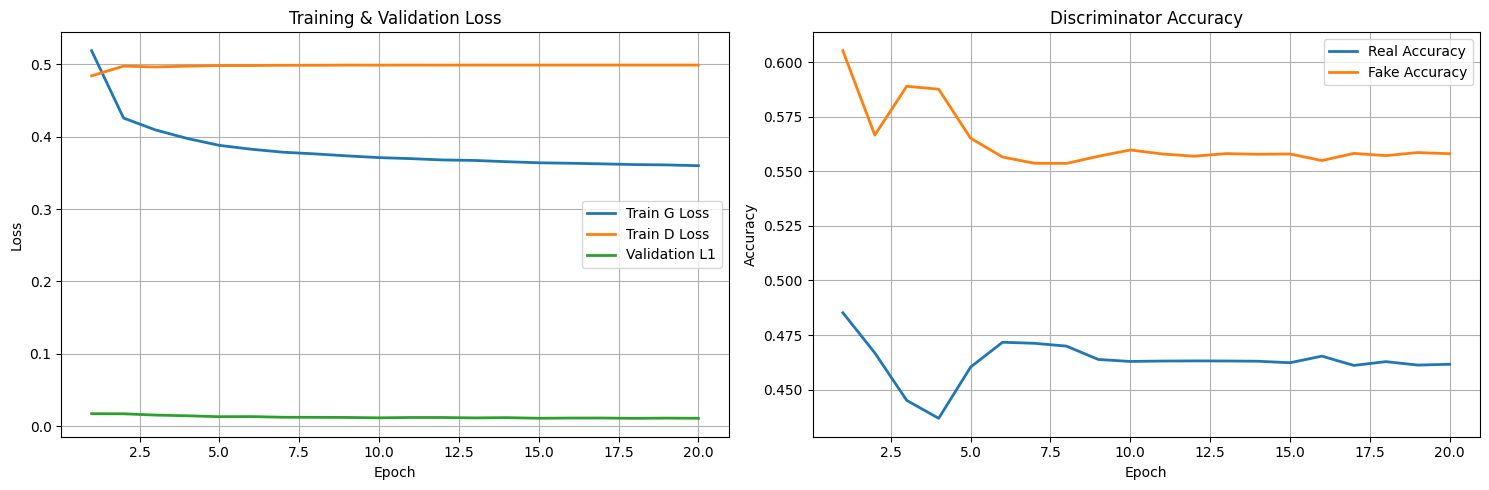

In [32]:
import json
import matplotlib.pyplot as plt


with open("training_log.json", "r") as f:
    data = json.load(f)

g_losses = data["g_losses"]
d_losses = data["d_losses"]
val_losses = data["val_losses"]
real_acc_list = data["real_acc"]
fake_acc_list = data["fake_acc"]

epochs = range(1, len(g_losses) + 1)

plt.figure(figsize=(15,5))

# ======================
# Loss Plot
# ======================
plt.subplot(1,2,1)

plt.plot(epochs, g_losses, label="Train G Loss", linewidth=2)
plt.plot(epochs, d_losses, label="Train D Loss", linewidth=2)
plt.plot(epochs, val_losses, label="Validation L1", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.grid(True)

# ======================
# Accuracy Plot
# ======================
plt.subplot(1,2,2)

plt.plot(epochs, real_acc_list, label="Real Accuracy", linewidth=2)
plt.plot(epochs, fake_acc_list, label="Fake Accuracy", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Discriminator Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

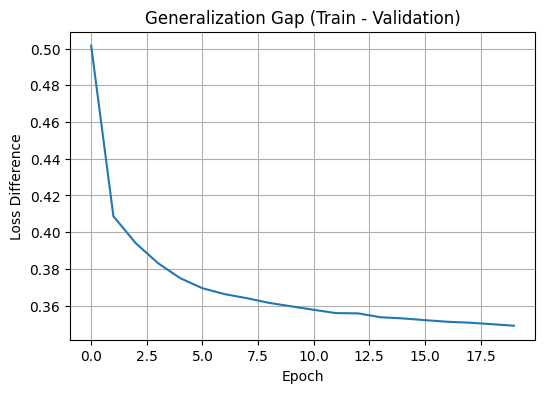

In [33]:
gap = [t - v for t, v in zip(g_losses, val_losses)]

plt.figure(figsize=(6,4))
plt.plot(gap)
plt.title("Generalization Gap (Train - Validation)")
plt.xlabel("Epoch")
plt.ylabel("Loss Difference")
plt.grid(True)
plt.show()

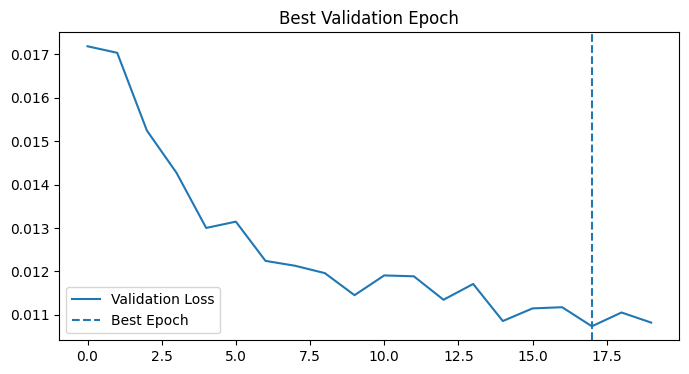

In [34]:
best_epoch = val_losses.index(min(val_losses)) + 1

plt.figure(figsize=(8,4))
plt.plot(val_losses, label="Validation Loss")
plt.axvline(best_epoch-1, linestyle="--", label="Best Epoch")
plt.legend()
plt.title("Best Validation Epoch")
plt.show()

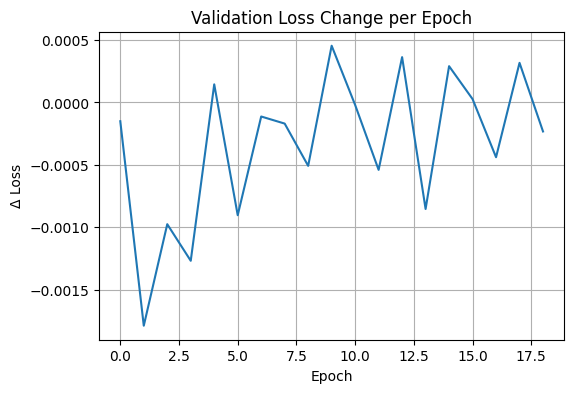

In [35]:
import numpy as np

loss_derivative = np.diff(val_losses)

plt.figure(figsize=(6,4))
plt.plot(loss_derivative)
plt.title("Validation Loss Change per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Δ Loss")
plt.grid(True)
plt.show()

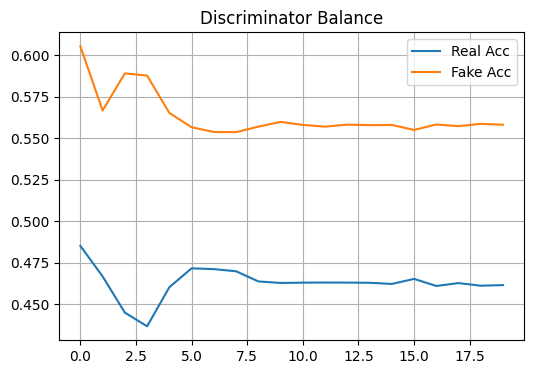

In [36]:
plt.figure(figsize=(6,4))
plt.plot(real_acc_list, label="Real Acc")
plt.plot(fake_acc_list, label="Fake Acc")
plt.title("Discriminator Balance")
plt.legend()
plt.grid(True)
plt.show()

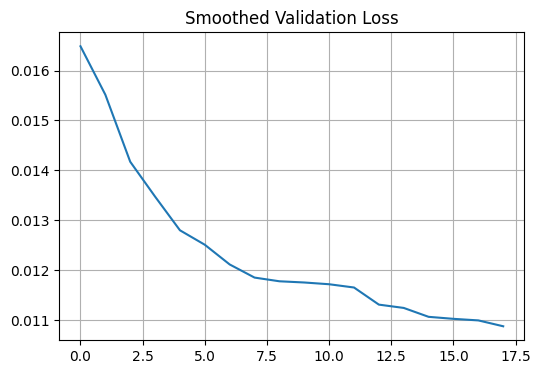

In [37]:
def moving_avg(x, k=3):
    return np.convolve(x, np.ones(k)/k, mode='valid')

plt.figure(figsize=(6,4))
plt.plot(moving_avg(val_losses,3))
plt.title("Smoothed Validation Loss")
plt.grid(True)
plt.show()

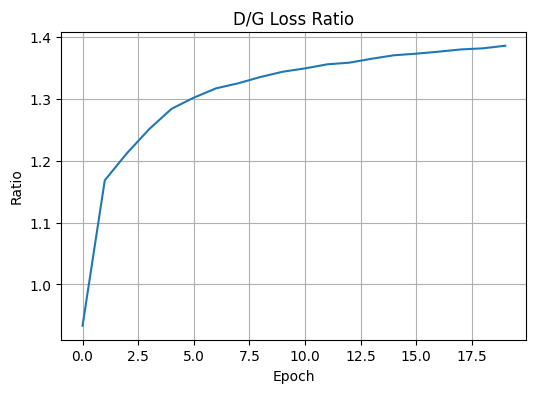

In [38]:
ratio = [d/g for d, g in zip(d_losses, g_losses)]

plt.figure(figsize=(6,4))
plt.plot(ratio)
plt.title("D/G Loss Ratio")
plt.xlabel("Epoch")
plt.ylabel("Ratio")
plt.grid(True)
plt.show()

# *Testing the Model on a Noisy Audio Sample*

In [39]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

G.load_state_dict(torch.load("G_best_val.pth", map_location=device))
G.to(device)
G.eval()

print("Best validation model loaded.")

Best validation model loaded.


In [40]:
import random

idx = random.randint(0, len(test_dataset) - 1)

noisy_wav, clean_wav = test_dataset[idx]

print("Selected sample index:", idx)

Selected sample index: 736


In [41]:
import random
import torch.nn.functional as F

idx = random.randint(0, len(test_dataset) - 1)

noisy_wav, clean_wav = test_dataset[idx]

print("Selected sample index:", idx)

segment_length = 16384

noisy_wav = noisy_wav.unsqueeze(0).to(device)  # (1,1,T)

segments = []
original_length = noisy_wav.shape[2]

for i in range(0, original_length, segment_length):
    segment = noisy_wav[:, :, i:i+segment_length]

    if segment.shape[2] < segment_length:
        segment = F.pad(segment, (0, segment_length - segment.shape[2]))

    segments.append(segment)

segments = torch.cat(segments, dim=0)

with torch.no_grad():
    enhanced_segments = G(segments)

enhanced_segments = enhanced_segments.cpu()

# reconstruct
enhanced_wav = enhanced_segments.reshape(-1)[:original_length]

torch.save(enhanced_wav, "enhanced_tensor.pt")

print("Enhanced audio generated.")

Selected sample index: 1037
Enhanced audio generated.


In [42]:
from IPython.display import Audio

print("Noisy:")
display(Audio(noisy_wav.squeeze().cpu().numpy(), rate=16000))

print("Clean Ground Truth:")
display(Audio(clean_wav.squeeze().numpy(), rate=16000))

print("Model Output:")
display(Audio(enhanced_wav.numpy(), rate=16000))

Noisy:


Clean Ground Truth:


Model Output:


In [43]:
min_len = min(
    clean_wav.shape[-1],
    noisy_wav.shape[-1],
    enhanced_wav.shape[-1]
)

clean_trim = clean_wav.squeeze()[:min_len]
noisy_trim = noisy_wav.squeeze().cpu()[:min_len]
enhanced_trim = enhanced_wav[:min_len]

In [44]:
import torch

def compute_snr(clean, signal):
    noise = clean - signal
    signal_power = torch.sum(clean ** 2)
    noise_power = torch.sum(noise ** 2)
    return 10 * torch.log10(signal_power / noise_power)

snr_before = compute_snr(clean_trim, noisy_trim)
snr_after = compute_snr(clean_trim, enhanced_trim)

print("SNR Before Enhancement:", snr_before.item())
print("SNR After Enhancement:", snr_after.item())
print("SNR Improvement:", (snr_after - snr_before).item())

SNR Before Enhancement: 3.784303665161133
SNR After Enhancement: 10.87343692779541
SNR Improvement: 7.089133262634277


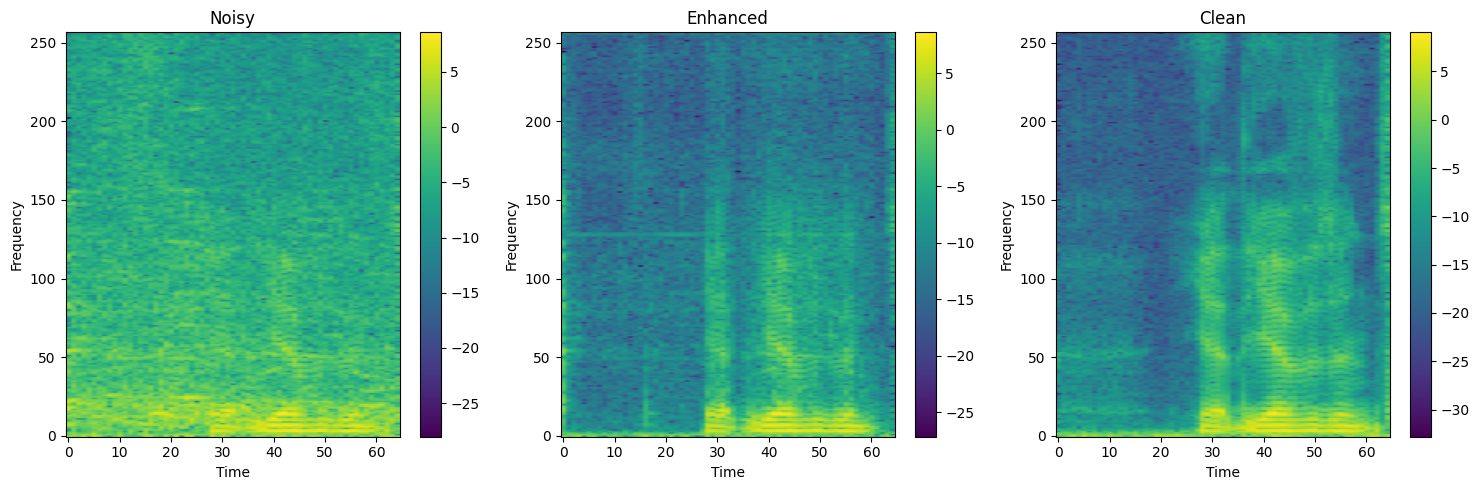

In [45]:
import matplotlib.pyplot as plt
import torchaudio

def plot_spectrogram(wav, title):
    spectrogram = torchaudio.transforms.Spectrogram(n_fft=512)(wav.unsqueeze(0))
    spectrogram = spectrogram.squeeze().log2()

    plt.imshow(spectrogram.numpy(), aspect="auto", origin="lower")
    plt.title(title)
    plt.colorbar()
    plt.xlabel("Time")
    plt.ylabel("Frequency")

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plot_spectrogram(noisy_trim, "Noisy")

plt.subplot(1,3,2)
plot_spectrogram(enhanced_trim, "Enhanced")

plt.subplot(1,3,3)
plot_spectrogram(clean_trim, "Clean")

plt.tight_layout()
plt.show()

# **Model Evaluation on My Own Voice Sample**

In [46]:
import os
print(os.listdir("/kaggle/input/datasets/taherehhematiyan/my-voice-test"))

['my_voice.wav']


In [47]:
import torchaudio
from IPython.display import Audio, display

file_path = "/kaggle/input/datasets/taherehhematiyan/my-voice-test/my_voice.wav"

wav, sr = torchaudio.load(file_path)

print("Sample Rate:", sr)
print("Shape:", wav.shape)

display(Audio(wav.squeeze().numpy(), rate=sr))

Sample Rate: 48000
Shape: torch.Size([2, 168960])


In [48]:
import torch

# mono
if wav.shape[0] > 1:
    wav = torch.mean(wav, dim=0, keepdim=True)

# resample
if sr != 16000:
    resampler = torchaudio.transforms.Resample(sr, 16000)
    wav = resampler(wav)

# normalize
wav = wav / wav.abs().max()

clean_wav = wav
print("New shape:", clean_wav.shape)

New shape: torch.Size([1, 56320])


In [49]:
def add_noise(signal, snr_db):
    noise = torch.randn_like(signal)

    signal_power = torch.mean(signal ** 2)
    noise_power = torch.mean(noise ** 2)

    desired_noise_power = signal_power / (10 ** (snr_db / 10))
    noise = noise * torch.sqrt(desired_noise_power / noise_power)

    return signal + noise

noisy_wav = add_noise(clean_wav, snr_db=3)

display(Audio(noisy_wav.squeeze().numpy(), rate=16000))

In [50]:
import torch.nn.functional as F
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
segment_length = 16384
original_length = noisy_wav.shape[1]

noisy_input = noisy_wav.unsqueeze(0).to(device)

segments = []

for i in range(0, original_length, segment_length):
    segment = noisy_input[:, :, i:i+segment_length]

    if segment.shape[2] < segment_length:
        segment = F.pad(segment, (0, segment_length - segment.shape[2]))

    segments.append(segment)

segments = torch.cat(segments, dim=0)

with torch.no_grad():
    enhanced_segments = G(segments)

enhanced_segments = enhanced_segments.cpu()
enhanced_wav = enhanced_segments.reshape(-1)[:original_length]

display(Audio(enhanced_wav.numpy(), rate=16000))

In [51]:
import random

# یک نمونه تصادفی از دیتاست train
idx = random.randint(0, len(train_dataset) - 1)

noisy_sample, clean_sample = train_dataset[idx]

# استخراج نویز واقعی
real_noise = noisy_sample - clean_sample

print("Noise shape:", real_noise.shape)

Noise shape: torch.Size([1, 16384])


In [52]:
import torch

target_length = clean_wav.shape[1]  # 56320

noise = real_noise

# اگر نویز کوتاه‌تره → repeat
if noise.shape[1] < target_length:
    repeat_factor = target_length // noise.shape[1] + 1
    noise = noise.repeat(1, repeat_factor)

# حالا crop کنیم دقیقاً هم‌اندازه بشه
noise = noise[:, :target_length]

print("Resized noise shape:", noise.shape)

Resized noise shape: torch.Size([1, 56320])


In [53]:
def mix_with_snr(clean, noise, snr_db):

    clean_power = torch.mean(clean ** 2)
    noise_power = torch.mean(noise ** 2)

    desired_noise_power = clean_power / (10 ** (snr_db / 10))
    noise = noise * torch.sqrt(desired_noise_power / noise_power)

    return clean + noise

noisy_realistic = mix_with_snr(clean_wav, noise, snr_db=3)

In [54]:
from IPython.display import Audio
Audio(noisy_realistic.squeeze().numpy(), rate=16000)

In [56]:
import torch.nn.functional as F
from IPython.display import Audio

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

segment_length = 16384

# اگر shape برابر [1, T] هست
original_length = noisy_realistic.shape[1]

noisy_input = noisy_realistic.unsqueeze(0).to(device)  # (1,1,T)

segments = []

for i in range(0, original_length, segment_length):

    segment = noisy_input[:, :, i:i+segment_length]

    if segment.shape[2] < segment_length:
        segment = F.pad(segment, (0, segment_length - segment.shape[2]))

    segments.append(segment)

segments = torch.cat(segments, dim=0)

with torch.no_grad():
    enhanced_segments = G(segments)

enhanced_segments = enhanced_segments.cpu()

# reconstruct waveform
enhanced_wav = enhanced_segments.reshape(-1)[:original_length]

display(Audio(enhanced_wav.numpy(), rate=16000))

In [57]:
print("Clean voice max:", clean_wav.abs().max())
print("Dataset clean max:", clean_sample.abs().max())

Clean voice max: tensor(1.)
Dataset clean max: tensor(0.4973)


In [58]:
target_max = clean_sample.abs().max()

clean_wav_matched = clean_wav * (target_max / clean_wav.abs().max())

print("New max:", clean_wav_matched.abs().max())

New max: tensor(0.4973)


In [59]:
noisy_realistic = mix_with_snr(clean_wav_matched, noise, snr_db=3)

In [61]:
import torch.nn.functional as F
from IPython.display import Audio

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

segment_length = 16384


original_length = noisy_realistic.shape[1]

noisy_input = noisy_realistic.unsqueeze(0).to(device)  # (1,1,T)

segments = []

for i in range(0, original_length, segment_length):

    segment = noisy_input[:, :, i:i+segment_length]

    if segment.shape[2] < segment_length:
        segment = F.pad(segment, (0, segment_length - segment.shape[2]))

    segments.append(segment)

segments = torch.cat(segments, dim=0)

with torch.no_grad():
    enhanced_segments = G(segments)

enhanced_segments = enhanced_segments.cpu()

# reconstruct waveform
enhanced_wav = enhanced_segments.reshape(-1)[:original_length]

display(Audio(enhanced_wav.numpy(), rate=16000))

In [62]:
import torch
import torch.nn.functional as F
from IPython.display import Audio, display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------
# 1. Distribution Match
# -----------------------------

dataset_max = clean_sample.abs().max()
clean_matched = clean_wav * (dataset_max / clean_wav.abs().max())

print("Matched max:", clean_matched.abs().max().item())

# -----------------------------
# 2. Resize Real Noise
# -----------------------------

target_length = clean_matched.shape[1]

noise = real_noise

if noise.shape[1] < target_length:
    repeat_factor = target_length // noise.shape[1] + 1
    noise = noise.repeat(1, repeat_factor)

noise = noise[:, :target_length]

# -----------------------------
# 3. Mix with SNR
# -----------------------------

def mix_with_snr(clean, noise, snr_db):

    clean_power = torch.mean(clean ** 2)
    noise_power = torch.mean(noise ** 2)

    desired_noise_power = clean_power / (10 ** (snr_db / 10))
    noise = noise * torch.sqrt(desired_noise_power / noise_power)

    return clean + noise

snr_test = 5   # عدد رو میتونی تغییر بدی
noisy_realistic = mix_with_snr(clean_matched, noise, snr_test)

# -----------------------------
# 4. Give to Model
# -----------------------------

segment_length = 16384
original_length = noisy_realistic.shape[1]

noisy_input = noisy_realistic.unsqueeze(0).to(device)

segments = []

for i in range(0, original_length, segment_length):

    segment = noisy_input[:, :, i:i+segment_length]

    if segment.shape[2] < segment_length:
        segment = F.pad(segment, (0, segment_length - segment.shape[2]))

    segments.append(segment)

segments = torch.cat(segments, dim=0)

with torch.no_grad():
    enhanced_segments = G(segments)

enhanced_segments = enhanced_segments.cpu()
enhanced_wav = enhanced_segments.reshape(-1)[:original_length]

# -----------------------------
# 5. Compute SNR
# -----------------------------

def compute_snr(clean, signal):
    noise = clean - signal
    return 10 * torch.log10(torch.sum(clean**2) / torch.sum(noise**2))

snr_before = compute_snr(clean_matched, noisy_realistic)
snr_after = compute_snr(clean_matched, enhanced_wav.unsqueeze(0))

print("SNR Before:", snr_before.item())
print("SNR After:", snr_after.item())
print("Improvement:", (snr_after - snr_before).item())

# -----------------------------
# 6. Listen
# -----------------------------

print("\nNoisy:")
display(Audio(noisy_realistic.squeeze().numpy(), rate=16000))

print("Enhanced:")
display(Audio(enhanced_wav.numpy(), rate=16000))

Matched max: 0.4972546696662903
SNR Before: 4.999999523162842
SNR After: 4.524893283843994
Improvement: -0.47510623931884766

Noisy:


Enhanced:


In [63]:
clean_input = clean_matched.unsqueeze(0).to(device)

with torch.no_grad():
    out = G(clean_input)

out = out.cpu().reshape(-1)

from IPython.display import Audio
Audio(out.numpy(), rate=16000)

In [64]:
snr_values = [3, 5, 8, 10]

for snr_test in snr_values:

    noisy_realistic = mix_with_snr(clean_matched, noise, snr_test)

    # ---- Segmenting ----
    segment_length = 16384
    original_length = noisy_realistic.shape[1]

    noisy_input = noisy_realistic.unsqueeze(0).to(device)

    segments = []

    for i in range(0, original_length, segment_length):
        segment = noisy_input[:, :, i:i+segment_length]

        if segment.shape[2] < segment_length:
            segment = F.pad(segment, (0, segment_length - segment.shape[2]))

        segments.append(segment)

    segments = torch.cat(segments, dim=0)

    with torch.no_grad():
        enhanced_segments = G(segments)

    enhanced_segments = enhanced_segments.cpu()
    enhanced_wav = enhanced_segments.reshape(-1)[:original_length]

    # ---- SNR ----
    snr_before = compute_snr(clean_matched, noisy_realistic)
    snr_after = compute_snr(clean_matched, enhanced_wav.unsqueeze(0))

    print(f"\nSNR Test: {snr_test} dB")
    print("Before:", snr_before.item())
    print("After :", snr_after.item())
    print("Improvement:", (snr_after - snr_before).item())


SNR Test: 3 dB
Before: 2.9999992847442627
After : 3.900754690170288
Improvement: 0.9007554054260254

SNR Test: 5 dB
Before: 4.999999523162842
After : 4.524893283843994
Improvement: -0.47510623931884766

SNR Test: 8 dB
Before: 7.999999523162842
After : 5.192666530609131
Improvement: -2.807332992553711

SNR Test: 10 dB
Before: 9.999999046325684
After : 5.500021934509277
Improvement: -4.499977111816406


# **Waveform Overlay**

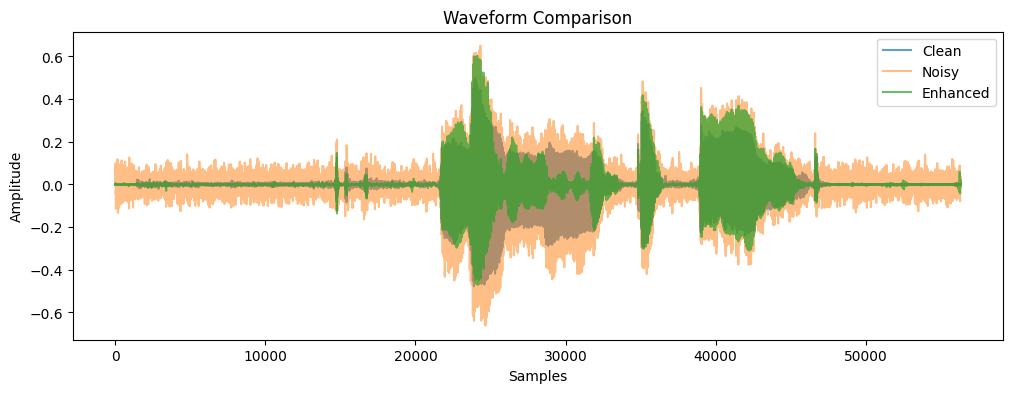

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.plot(clean_matched.squeeze().numpy(), label="Clean", alpha=0.7)
plt.plot(noisy_realistic.squeeze().numpy(), label="Noisy", alpha=0.5)
plt.plot(enhanced_wav.numpy(), label="Enhanced", alpha=0.7)

plt.legend()
plt.title("Waveform Comparison")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.show()

# **Error Signal**

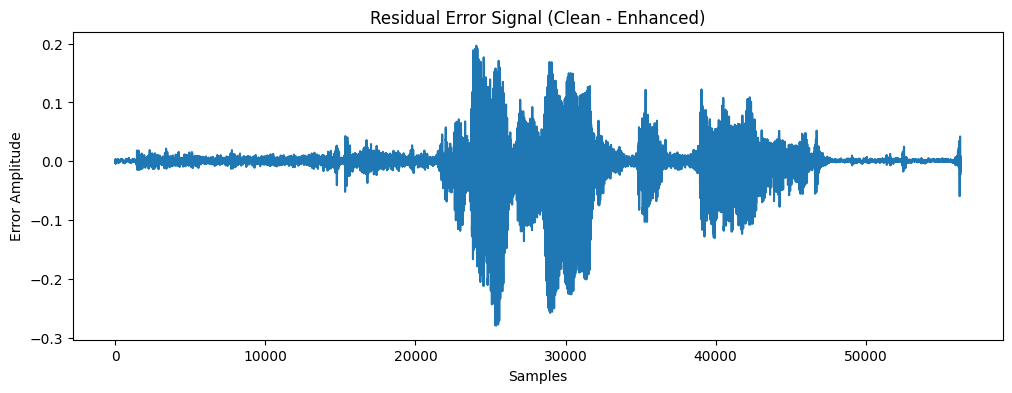

In [73]:
error_signal = clean_matched.squeeze() - enhanced_wav

plt.figure(figsize=(12,4))
plt.plot(error_signal.numpy())
plt.title("Residual Error Signal (Clean - Enhanced)")
plt.xlabel("Samples")
plt.ylabel("Error Amplitude")
plt.show()

# **RMS Energy Comparison**

In [74]:
def rms(x):
    return torch.sqrt(torch.mean(x**2))

print("Clean RMS:", rms(clean_matched).item())
print("Noisy RMS:", rms(noisy_realistic).item())
print("Enhanced RMS:", rms(enhanced_wav).item())

Clean RMS: 0.07025925070047379
Noisy RMS: 0.10386461019515991
Enhanced RMS: 0.06964276731014252


# **High-Frequency Energy**

In [75]:
import torch.fft as fft

def high_freq_energy(x):

    spec = torch.abs(fft.rfft(x))
    freqs = torch.linspace(0, 8000, spec.shape[0])

    mask = freqs > 4000  # بالای 4kHz
    return torch.mean(spec[mask])

print("HF Clean:", high_freq_energy(clean_matched.squeeze()).item())
print("HF Enhanced:", high_freq_energy(enhanced_wav).item())

HF Clean: 0.7543925642967224
HF Enhanced: 0.8276100754737854


# **Spectrogram Difference**

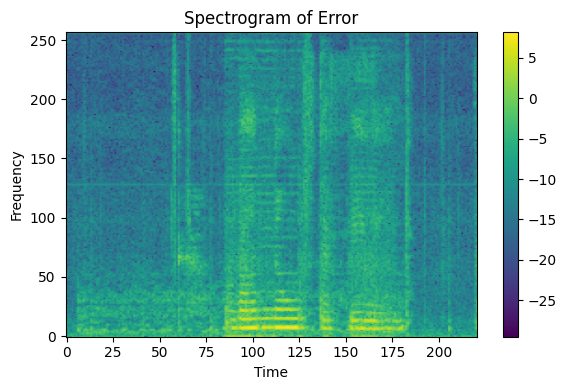

In [76]:
plt.figure(figsize=(6,4))
plot_spectrogram(error_signal, "Spectrogram of Error")
plt.tight_layout()
plt.show()